In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
from sklearn import base


In [10]:
df_train= pd.read_csv('train.csv')
df_train.head(5)

                

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [11]:
X = df_train.drop(['SalePrice'], axis= 1)
Y = df_train['SalePrice']

In [12]:
X

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal


In [13]:
Y

0       208500
1       181500
2       223500
3       140000
4       250000
         ...  
1455    175000
1456    210000
1457    266500
1458    142125
1459    147500
Name: SalePrice, Length: 1460, dtype: int64

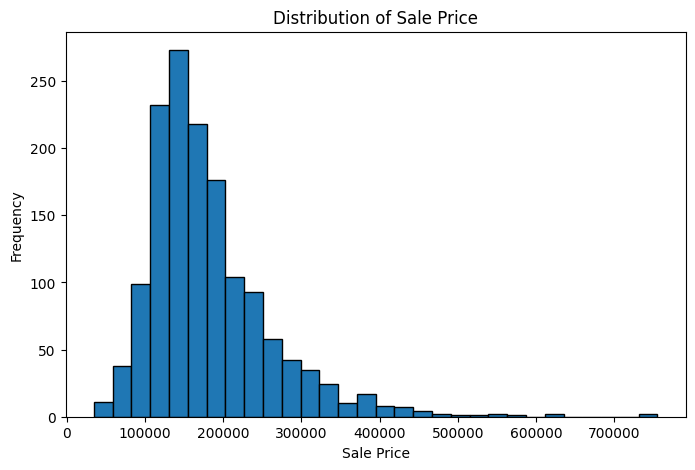

In [14]:

plt.figure(figsize=(8, 5))
plt.hist(Y, bins=30, edgecolor='black')
plt.title('Distribution of Sale Price')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.show()

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split  
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

X = df_train.drop(columns=['SalePrice'])
Y = df_train['SalePrice']

X_encoded = pd.get_dummies(X, drop_first=True)
X_encoded = X_encoded.fillna(0)

def train_model(X_data, Y_data):
    X_train, X_test, Y_train, Y_test = train_test_split(X_data, Y_data, test_size=0.2, random_state=42)
    
    model = LinearRegression()
    model.fit(X_train, Y_train)
    
    predictions = model.predict(X_test)
    mae = mean_absolute_error(Y_test, predictions)
    r2 = r2_score(Y_test, predictions)
    
    print('Mean Absolute Error: {:.2f}'.format(mae))
    print('R2 Score: {:.4f}'.format(r2))
    return model

trained_model = train_model(X_encoded, Y)


Mean Absolute Error: 20513.17
R2 Score: 0.6817


In [16]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

encoded_df = pd.DataFrame()
label = LabelEncoder()

for c in df_train.columns:
    if df_train[c].dtype == 'object':
        encoded_df[c] = label.fit_transform(df_train[c].astype(str))
    else:
        encoded_df[c] = df_train[c]

encoded_df.head(5)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,3,65.0,8450,1,2,3,3,0,...,0,3,4,4,0,2,2008,8,4,208500
1,2,20,3,80.0,9600,1,2,3,3,0,...,0,3,4,4,0,5,2007,8,4,181500
2,3,60,3,68.0,11250,1,2,0,3,0,...,0,3,4,4,0,9,2008,8,4,223500
3,4,70,3,60.0,9550,1,2,0,3,0,...,0,3,4,4,0,2,2006,8,0,140000
4,5,60,3,84.0,14260,1,2,0,3,0,...,0,3,4,4,0,12,2008,8,4,250000


In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

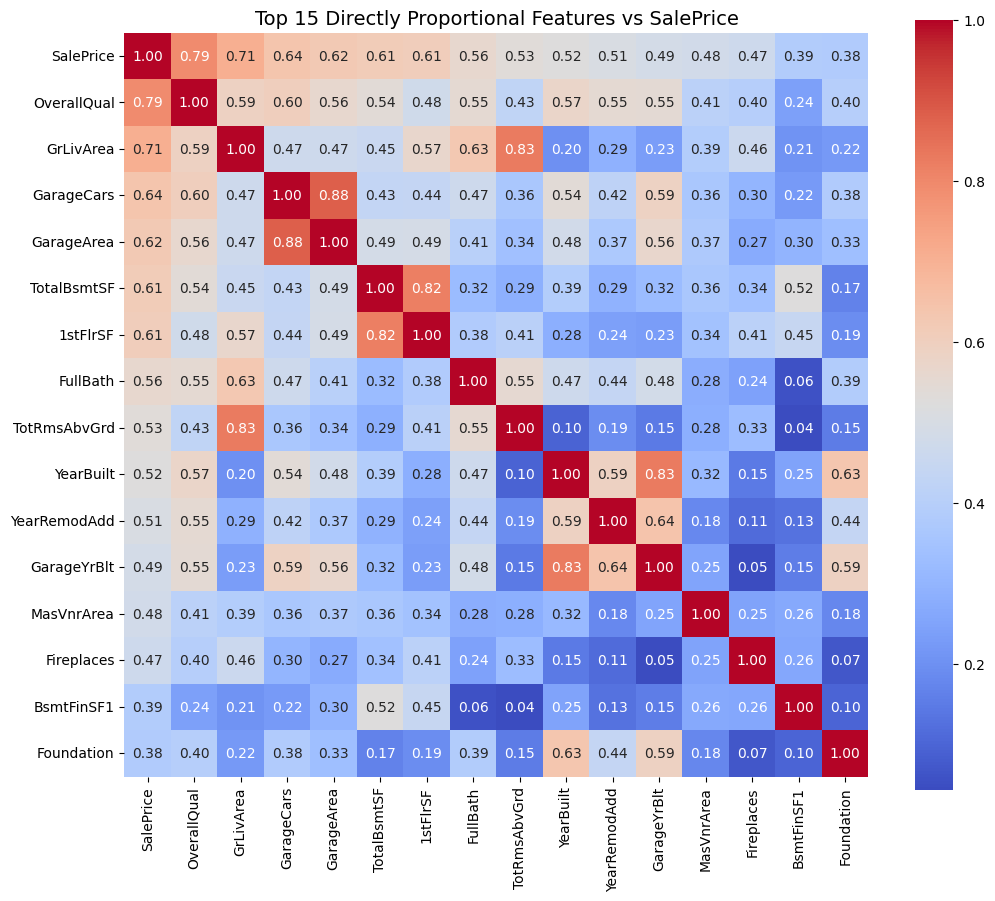

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

price_correlations = encoded_df.corr()['SalePrice'].sort_values(ascending=False)

top_15_pos = price_correlations.index[1:16].tolist()
pos_matrix_30 = encoded_df[['SalePrice'] + top_15_pos].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(pos_matrix_30, annot=True, cmap='coolwarm', fmt='.2f', square=True)
plt.title('Top 15 Directly Proportional Features vs SalePrice', fontsize=14)
plt.show()

Mean Absolute Error: 16577.35
R2 Score: 0.8874


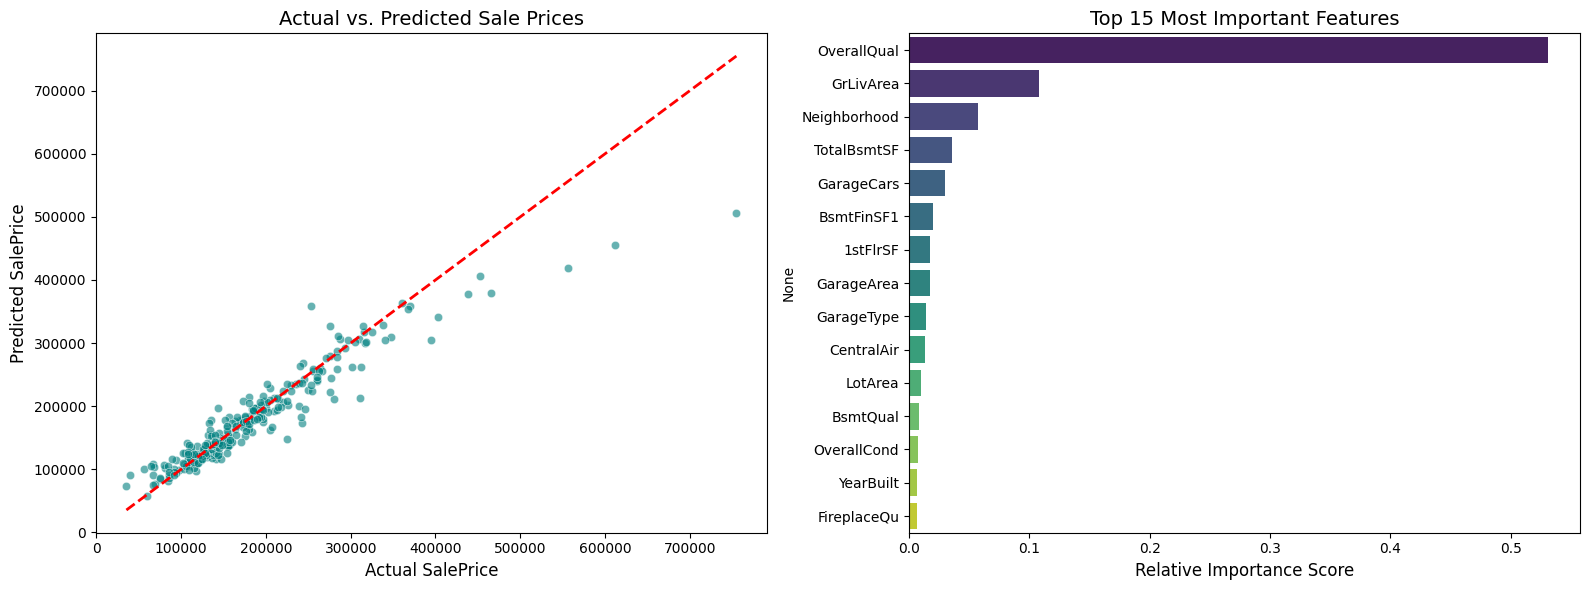

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Separate Features and Target
X = df_train.drop(columns=['SalePrice'])
Y = df_train['SalePrice']

# 2. Split into Train and Test sets
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# 3. Identify categorical columns
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

# 4. Apply Target Encoding
encoder = TargetEncoder(smooth="auto", cv=5, target_type="continuous", random_state=42)

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

X_train_encoded[categorical_cols] = encoder.fit_transform(X_train[categorical_cols], Y_train)
X_test_encoded[categorical_cols] = encoder.transform(X_test[categorical_cols])

# 5. Modeling Function
def train_model(X_tr, X_te, Y_tr, Y_te):
    Y_tr_log = np.log1p(Y_tr)
    
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_tr, Y_tr_log)
    
    predictions_log = model.predict(X_te)
    predictions = np.expm1(predictions_log)
    
    mae = mean_absolute_error(Y_te, predictions)
    r2 = r2_score(Y_te, predictions)
    
    print('Mean Absolute Error: {:.2f}'.format(mae))
    print('R2 Score: {:.4f}'.format(r2))
    
    return model, predictions

# 6. Train the model and get predictions
trained_model, y_pred = train_model(X_train_encoded, X_test_encoded, Y_train, Y_test)

# 7. Function to generate graphs (Updated to modern Seaborn syntax)
def plot_results(model, X_te, Y_te, predictions):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Graph 1: Actual vs Predicted Scatter Plot
    sns.scatterplot(x=Y_te, y=predictions, alpha=0.6, ax=axes[0], color='teal')
    axes[0].plot([Y_te.min(), Y_te.max()], [Y_te.min(), Y_te.max()], 'r--', lw=2)
    axes[0].set_title('Actual vs. Predicted Sale Prices', fontsize=14)
    axes[0].set_xlabel('Actual SalePrice', fontsize=12)
    axes[0].set_ylabel('Predicted SalePrice', fontsize=12)
    
    # Graph 2: Top 15 Feature Importances (Fixed warning by adding hue and legend)
    importances = model.feature_importances_
    feat_importances = pd.Series(importances, index=X_te.columns)
    top_features = feat_importances.nlargest(15)
    
    sns.barplot(
        x=top_features.values, 
        y=top_features.index, 
        ax=axes[1], 
        palette='viridis', 
        hue=top_features.index, 
        legend=False
    )
    axes[1].set_title('Top 15 Most Important Features', fontsize=14)
    axes[1].set_xlabel('Relative Importance Score', fontsize=12)
    
    plt.tight_layout()
    plt.show()

# Run the plotting function
plot_results(trained_model, X_test_encoded, Y_test, y_pred)


Mean Absolute Error: 17628.05
R2 Score: 0.8844


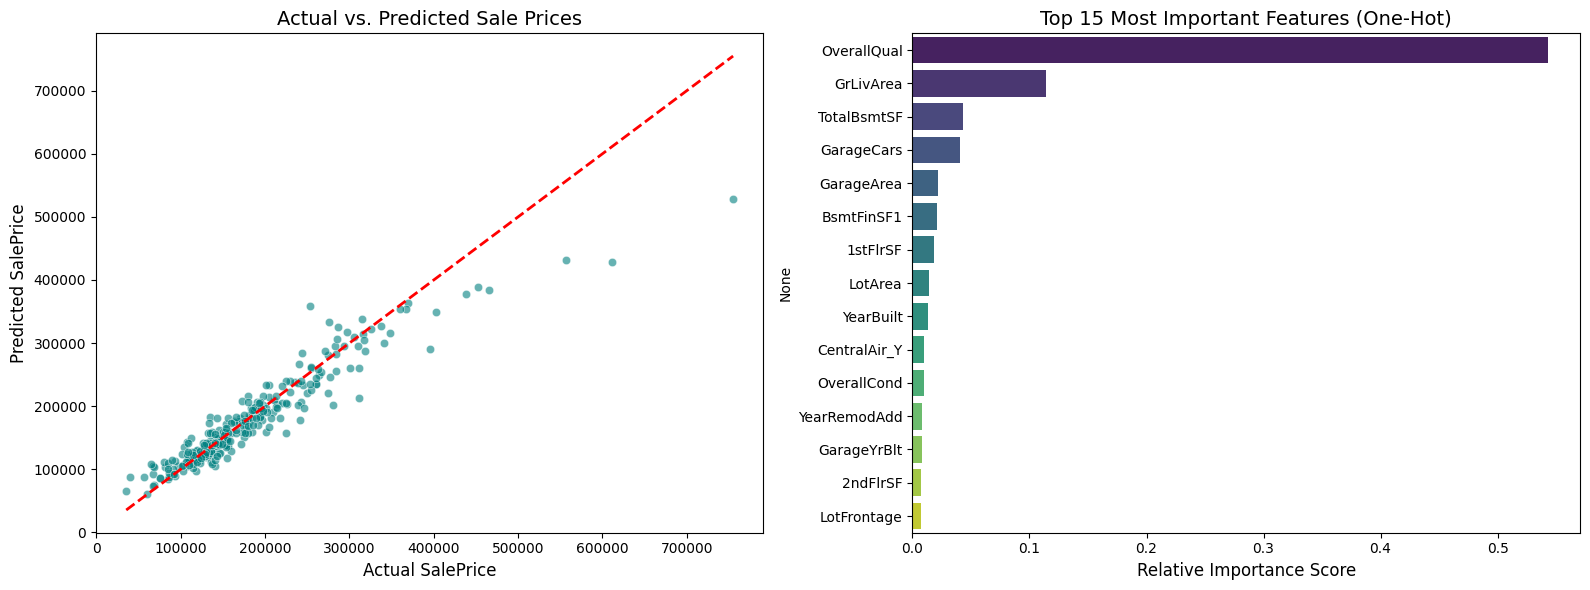

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

X = df_train.drop(columns=['SalePrice'])
Y = df_train['SalePrice']

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)


X_train_encoded = pd.get_dummies(X_train, dummy_na=True)
X_test_encoded = pd.get_dummies(X_test, dummy_na=True)


X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded, join='left', axis=1, fill_value=0
)
ef train_model(X_tr, X_te, Y_tr, Y_te):
    Y_tr_log = np.log1p(Y_tr)
    
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_tr, Y_tr_log)
    
    predictions_log = model.predict(X_te)
    predictions = np.expm1(predictions_log)
    
    mae = mean_absolute_error(Y_te, predictions)
    r2 = r2_score(Y_te, predictions)
    
    print('Mean Absolute Error: {:.2f}'.format(mae))
    print('R2 Score: {:.4f}'.format(r2))
    
    return model, predictions

trained_model, y_pred = train_model(X_train_encoded, X_test_encoded, Y_train, Y_test)


def plot_results(model, X_te, Y_te, predictions):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
   
    sns.scatterplot(x=Y_te, y=predictions, alpha=0.6, ax=axes[0], color='teal')
    axes[0].plot([Y_te.min(), Y_te.max()], [Y_te.min(), Y_te.max()], 'r--', lw=2)
    axes[0].set_title('Actual vs. Predicted Sale Prices', fontsize=14)
    axes[0].set_xlabel('Actual SalePrice', fontsize=12)
    axes[0].set_ylabel('Predicted SalePrice', fontsize=12)
    
   
    importances = model.feature_importances_
    feat_importances = pd.Series(importances, index=X_te.columns)
    top_features = feat_importances.nlargest(15)
    
    sns.barplot(
        x=top_features.values, 
        y=top_features.index, 
        ax=axes[1], 
        palette='viridis', 
        hue=top_features.index, 
        legend=False
    )
    axes[1].set_title('Top 15 Most Important Features (One-Hot)', fontsize=14)
    axes[1].set_xlabel('Relative Importance Score', fontsize=12)
    
    plt.tight_layout()
    plt.show()


plot_results(trained_model, X_test_encoded, Y_test, y_pred)


Mean Absolute Error: 15070.34
R2 Score: 0.9316


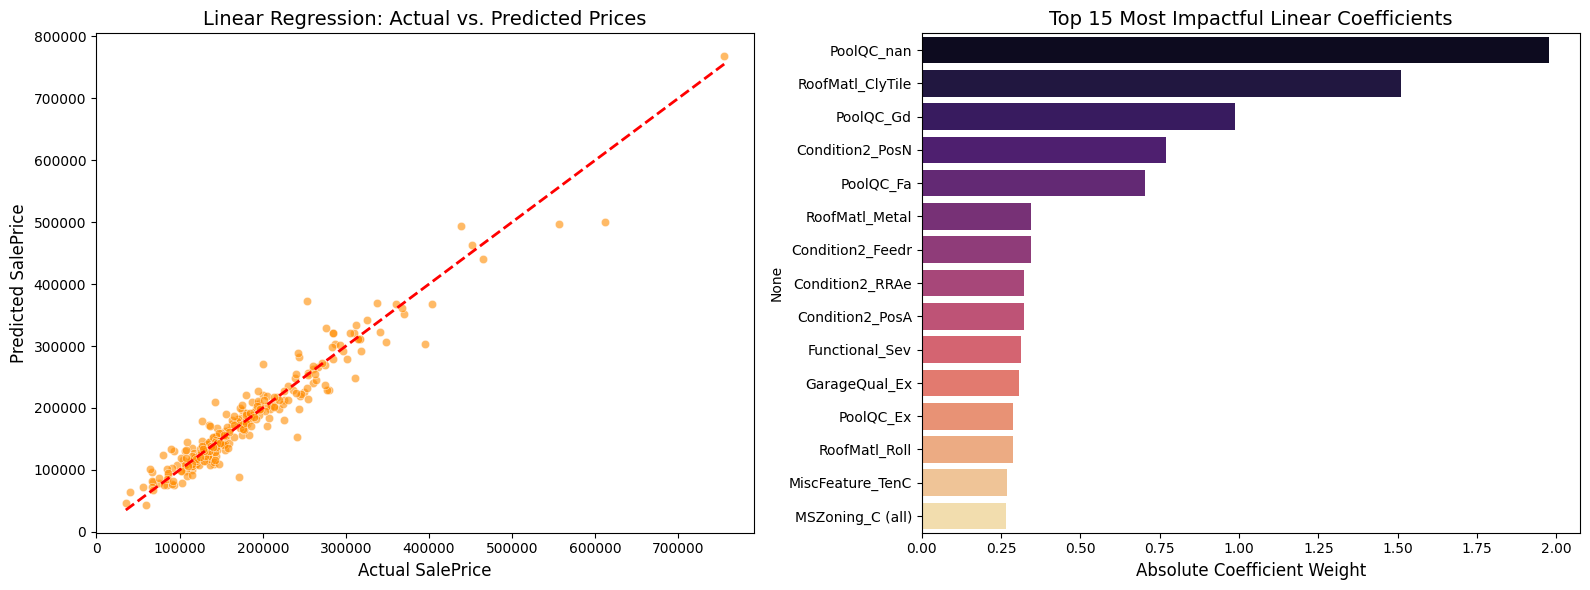

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


X = df_train.drop(columns=['SalePrice'])
Y = df_train['SalePrice']

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

numerical_cols = X_train.select_dtypes(include=[np.number]).columns
for col in numerical_cols:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

X_train_encoded = pd.get_dummies(X_train, dummy_na=True)
X_test_encoded = pd.get_dummies(X_test, dummy_na=True)

X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded, join='left', axis=1, fill_value=0
)


def train_linear_model(X_tr, X_te, Y_tr, Y_te):
 
    Y_tr_log = np.log1p(Y_tr)
    
    model = LinearRegression(n_jobs=-1)
    model.fit(X_tr, Y_tr_log)
    
    predictions_log = model.predict(X_te)
    predictions = np.expm1(predictions_log)
    

    mae = mean_absolute_error(Y_te, predictions)
    r2 = r2_score(Y_te, predictions)
    
    print('Mean Absolute Error: {:.2f}'.format(mae))
    print('R2 Score: {:.4f}'.format(r2))
    
    return model, predictions


trained_linear_model, y_pred = train_linear_model(X_train_encoded, X_test_encoded, Y_train, Y_test)

def plot_linear_results(model, X_te, Y_te, predictions):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
   
    sns.scatterplot(x=Y_te, y=predictions, alpha=0.6, ax=axes[0], color='darkorange')
    axes[0].plot([Y_te.min(), Y_te.max()], [Y_te.min(), Y_te.max()], 'r--', lw=2)
    axes[0].set_title('Linear Regression: Actual vs. Predicted Prices', fontsize=14)
    axes[0].set_xlabel('Actual SalePrice', fontsize=12)
    axes[0].set_ylabel('Predicted SalePrice', fontsize=12)
    
   
    coefficients = np.abs(model.coef_)
    coef_series = pd.Series(coefficients, index=X_te.columns)
    top_coefficients = coef_series.nlargest(15)
    
    sns.barplot(
        x=top_coefficients.values, 
        y=top_coefficients.index, 
        ax=axes[1], 
        palette='magma', 
        hue=top_coefficients.index, 
        legend=False
    )
    axes[1].set_title('Top 15 Most Impactful Linear Coefficients', fontsize=14)
    axes[1].set_xlabel('Absolute Coefficient Weight', fontsize=12)
    
    plt.tight_layout()
    plt.show()


plot_linear_results(trained_linear_model, X_test_encoded, Y_test, y_pred)



Mean Absolute Error: 17526.59
R2 Score: 0.8883


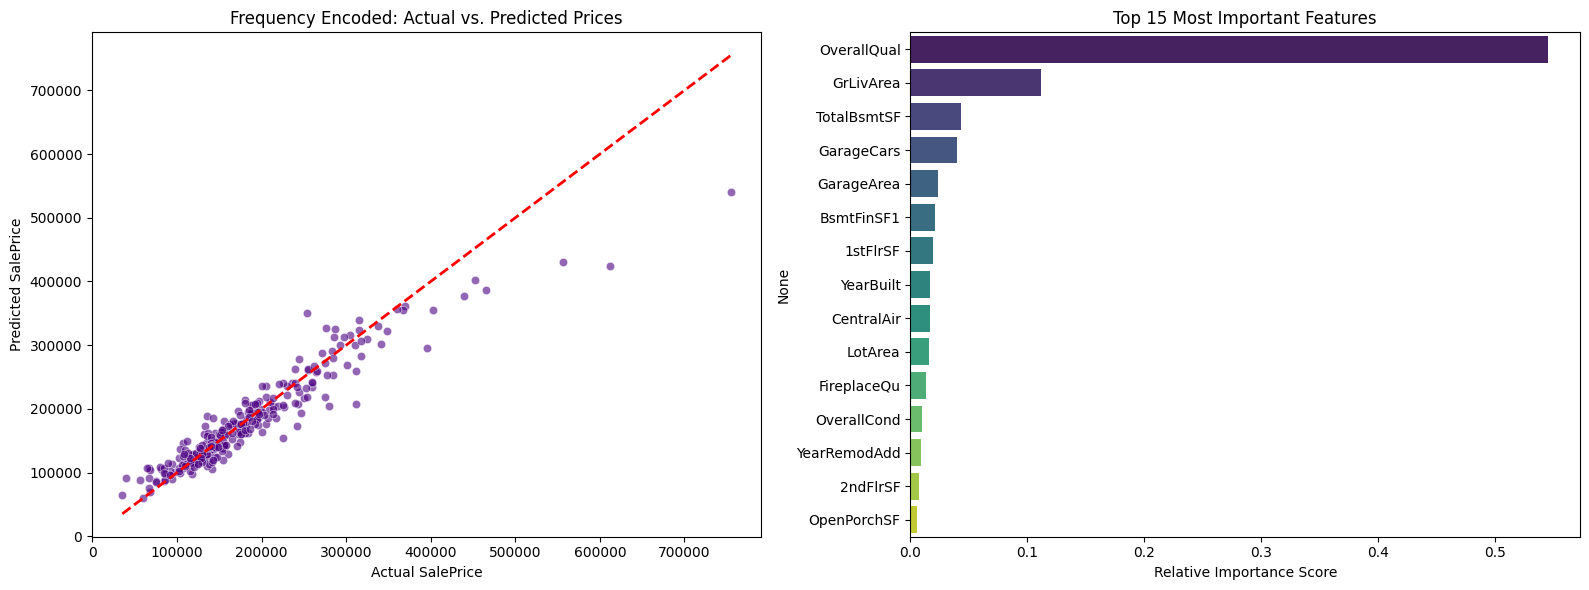

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score


X = df_train.drop(columns=['SalePrice'])
Y = df_train['SalePrice']


X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

for col in numerical_cols:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

for col in categorical_cols:

    freq_map = X_train[col].value_counts()
    

    X_train_encoded[col] = X_train[col].map(freq_map).fillna(0)
    X_test_encoded[col] = X_test[col].map(freq_map).fillna(0)


def train_model(X_tr, X_te, Y_tr, Y_te):
    Y_tr_log = np.log1p(Y_tr)
    
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_tr, Y_tr_log)
    
    predictions_log = model.predict(X_te)
    predictions = np.expm1(predictions_log)
    
    mae = mean_absolute_error(Y_te, predictions)
    r2 = r2_score(Y_te, predictions)
    
    print('Mean Absolute Error: {:.2f}'.format(mae))
    print('R2 Score: {:.4f}'.format(r2))
    
    return model, predictions

trained_model, y_pred = train_model(X_train_encoded, X_test_encoded, Y_train, Y_test)

def plot_results(model, X_te, Y_te, predictions):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    sns.scatterplot(x=Y_te, y=predictions, alpha=0.6, ax=axes[0], color='indigo')
    axes[0].plot([Y_te.min(), Y_te.max()], [Y_te.min(), Y_te.max()], 'r--', lw=2)
    axes[0].set_title('Frequency Encoded: Actual vs. Predicted Prices')
    axes[0].set_xlabel('Actual SalePrice')
    axes[0].set_ylabel('Predicted SalePrice')
    
    importances = model.feature_importances_
    feat_importances = pd.Series(importances, index=X_te.columns)
    top_features = feat_importances.nlargest(15)
    
    sns.barplot(x=top_features.values, y=top_features.index, ax=axes[1], palette='viridis', hue=top_features.index, legend=False)
    axes[1].set_title('Top 15 Most Important Features')
    axes[1].set_xlabel('Relative Importance Score')
    
    plt.tight_layout()
    plt.show()

plot_results(trained_model, X_test_encoded, Y_test, y_pred)


Mean Absolute Error: 17161.76
R2 Score: 0.8938


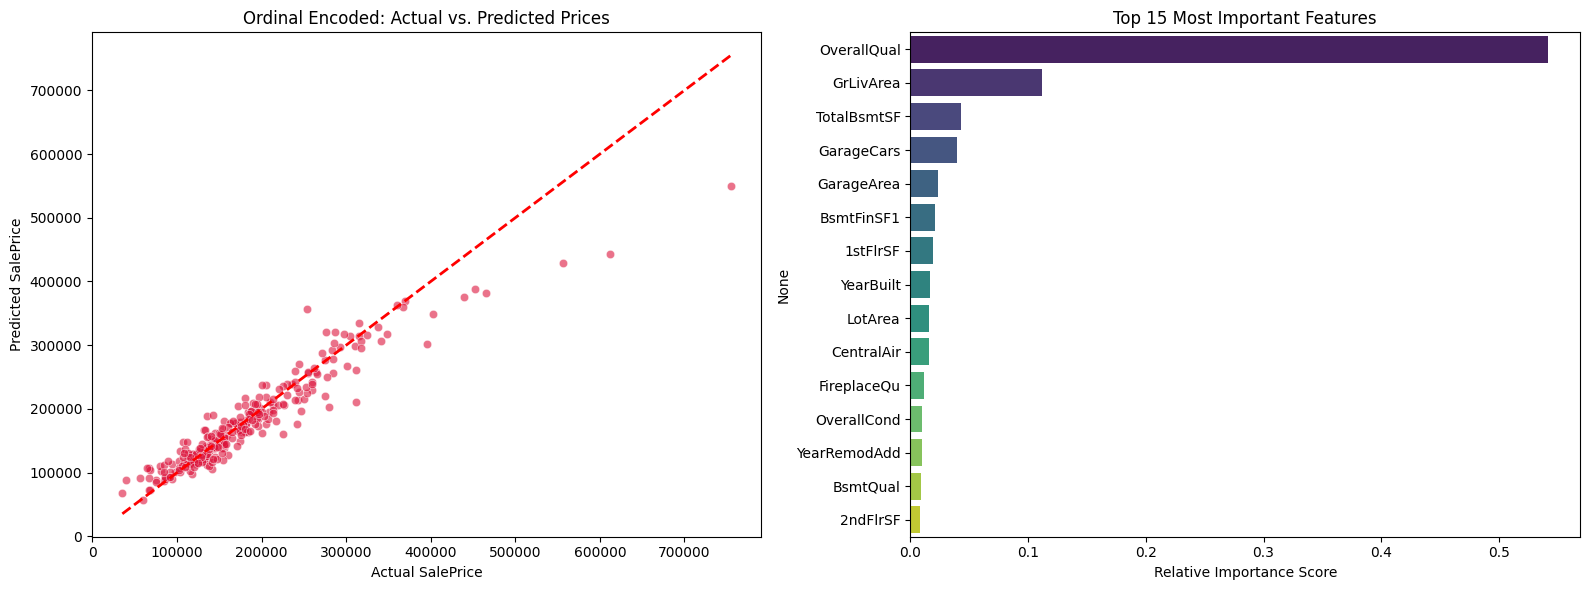

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
X = df_train.drop(columns=['SalePrice'])
Y = df_train['SalePrice']


X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)


numerical_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
for col in numerical_cols:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

# 4. Define Ordinal Rank Maps
quality_map = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'NA': 0, np.nan: 0}
exposure_map = {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'NA': 0, np.nan: 0}
functional_map = {'Typ': 7, 'Min1': 6, 'Min2': 5, 'Mod': 4, 'Maj1': 3, 'Maj2': 2, 'Sev': 1, 'Sal': 0, np.nan: 7}


ordinal_cols_quality = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']


X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()


for col in X_train.columns:
    if col in ordinal_cols_quality:
        X_train_encoded[col] = X_train[col].map(quality_map).fillna(0)
        X_test_encoded[col] = X_test[col].map(quality_map).fillna(0)
    elif col == 'BsmtExposure':
        X_train_encoded[col] = X_train[col].map(exposure_map).fillna(0)
        X_test_encoded[col] = X_test[col].map(exposure_map).fillna(0)
    elif col == 'Functional':
        X_train_encoded[col] = X_train[col].map(functional_map).fillna(7)
        X_test_encoded[col] = X_test[col].map(functional_map).fillna(7)

# Convert any remaining unmapped text columns to fallback codes (Factorize)
categorical_cols = X_train_encoded.select_dtypes(include=['object']).columns.tolist()
for col in categorical_cols:
    X_train_encoded[col], uniques = pd.factorize(X_train_encoded[col])
    X_test_encoded[col] = pd.Categorical(X_test_encoded[col], categories=uniques).codes

# 5. Modeling Function
def train_model(X_tr, X_te, Y_tr, Y_te):
    Y_tr_log = np.log1p(Y_tr)
    
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_tr, Y_tr_log)
    
    predictions_log = model.predict(X_te)
    predictions = np.expm1(predictions_log)
    
    mae = mean_absolute_error(Y_te, predictions)
    r2 = r2_score(Y_te, predictions)
    
    print('Mean Absolute Error: {:.2f}'.format(mae))
    print('R2 Score: {:.4f}'.format(r2))
    
    return model, predictions


trained_model, y_pred = train_model(X_train_encoded, X_test_encoded, Y_train, Y_test)

def plot_results(model, X_te, Y_te, predictions):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
  
    sns.scatterplot(x=Y_te, y=predictions, alpha=0.6, ax=axes[0], color='crimson')
    axes[0].plot([Y_te.min(), Y_te.max()], [Y_te.min(), Y_te.max()], 'r--', lw=2)
    axes[0].set_title('Ordinal Encoded: Actual vs. Predicted Prices')
    axes[0].set_xlabel('Actual SalePrice')
    axes[0].set_ylabel('Predicted SalePrice')
    

    importances = model.feature_importances_
    feat_importances = pd.Series(importances, index=X_te.columns)
    top_features = feat_importances.nlargest(15)
    
    sns.barplot(x=top_features.values, y=top_features.index, ax=axes[1], palette='viridis', hue=top_features.index, legend=False)
    axes[1].set_title('Top 15 Most Important Features')
    axes[1].set_xlabel('Relative Importance Score')
    
    plt.tight_layout()
    plt.show()

plot_results(trained_model, X_test_encoded, Y_test, y_pred)
